In [1]:
INTERVAL = "1h"
RAW_DIR  = "raw"
OUT_DIR  = "processed"
WEEKLY   = True       # a year of hourly data supports the weekly cycle
GAP_LIMIT = 6         # longest gap (bars) we interpolate

import numpy as np, pandas as pd, networkx as nx, pickle
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.tsa.seasonal import MSTL

Path(OUT_DIR).mkdir(exist_ok=True)
PD_FREQ = INTERVAL.replace("m", "min") if INTERVAL.endswith("m") else INTERVAL
BARS_PER_DAY = int(pd.Timedelta("1D") / pd.Timedelta(PD_FREQ))
universe = pd.read_csv(f"{RAW_DIR}/universe_{INTERVAL}.csv").symbol.tolist()
print(len(universe), "coins:", universe)

10 coins: ['BTCUSDT', 'ETHUSDT', 'SOLUSDT', 'XRPUSDT', 'ZECUSDT', 'DOGEUSDT', 'SUIUSDT', 'TRXUSDT', 'ADAUSDT', 'PAXGUSDT']


## Variable construction (per coin)

In [2]:
def build_vars(sym):
    kl = pd.read_csv(f"{RAW_DIR}/spot_{sym}_{INTERVAL}.csv")
    kl.index = pd.to_datetime(kl["open_time"], unit="ms")
    kl = kl.astype(float)
    fu = pd.read_csv(f"{RAW_DIR}/perp_{sym}_{INTERVAL}.csv")
    fu.index = pd.to_datetime(fu["open_time"], unit="ms")
    fu = fu.astype(float)

    d = pd.DataFrame(index=kl.index)
    d["p"]     = kl.close
    return d

raw_vars = {s: build_vars(s) for s in universe}
print({s: v.shape for s, v in list(raw_vars.items())[:3]})
print("\nNaNs (first coin):\n", raw_vars[universe[0]].isna().sum())

{'BTCUSDT': (8760, 1), 'ETHUSDT': (8760, 1), 'SOLUSDT': (8760, 1)}

NaNs (first coin):
 p    0
dtype: int64


## Gap filling + MSTL detrend/deseasonalize, per coin

MSTL needs complete series, so small gaps are interpolated and anything
longer than `GAP_LIMIT` is dropped. Only the **residual** component is
kept, then standardized.

In [3]:
periods = (BARS_PER_DAY, 7*BARS_PER_DAY) if WEEKLY else BARS_PER_DAY

def process(d):
    n0 = int(d.isna().sum().sum())
    d = d.interpolate(limit=GAP_LIMIT, limit_area="inside").dropna()
    res = pd.DataFrame({c: MSTL(d[c], periods=periods).fit().resid
                        for c in d.columns}, index=d.index)
    return (res - res.mean()), n0

proc = {}
for s in universe:
    proc[s], n0 = process(raw_vars[s])
    print(f"{s}: {proc[s].shape[0]} bars kept ({n0} NaN cells handled)")

BTCUSDT: 8760 bars kept (0 NaN cells handled)
ETHUSDT: 8760 bars kept (0 NaN cells handled)
SOLUSDT: 8760 bars kept (0 NaN cells handled)
XRPUSDT: 8760 bars kept (0 NaN cells handled)
ZECUSDT: 8760 bars kept (0 NaN cells handled)
DOGEUSDT: 8760 bars kept (0 NaN cells handled)
SUIUSDT: 8760 bars kept (0 NaN cells handled)
TRXUSDT: 8760 bars kept (0 NaN cells handled)
ADAUSDT: 8760 bars kept (0 NaN cells handled)
PAXGUSDT: 8760 bars kept (0 NaN cells handled)


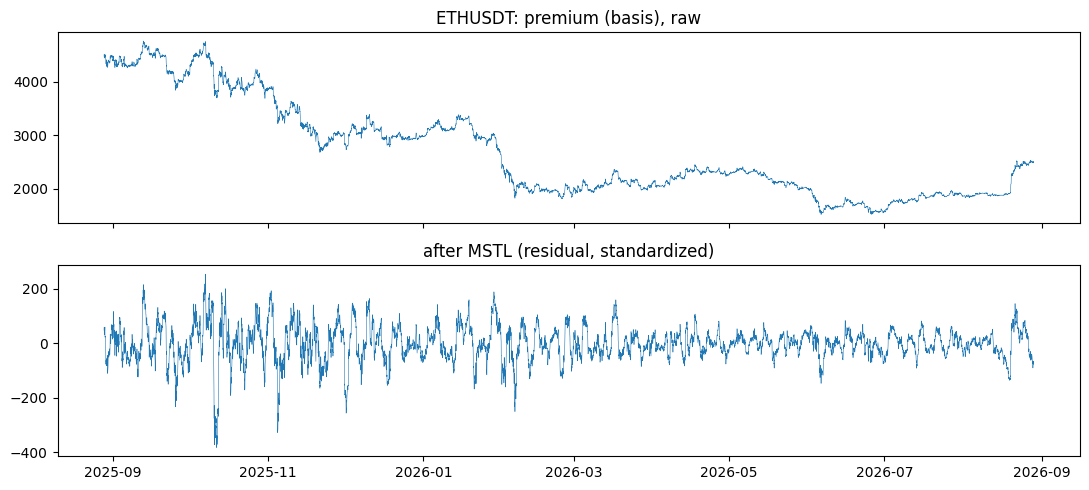

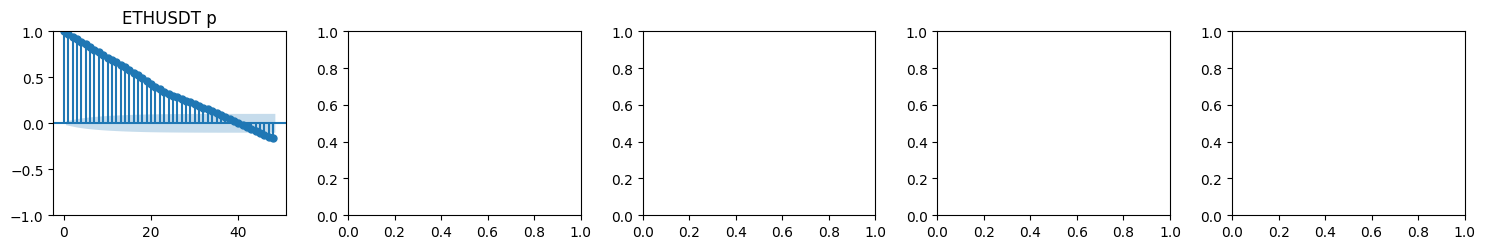

In [5]:
s0 = universe[1]
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(raw_vars[s0].index, raw_vars[s0]["p"], lw=0.4)
axes[0].set_title(f"{s0}: premium (basis), raw")
axes[1].plot(proc[s0].index, proc[s0]["p"], lw=0.4)
axes[1].set_title("after MSTL (residual, standardized)")
fig.tight_layout(); plt.show()

from statsmodels.graphics.tsaplots import plot_acf
fig, axes = plt.subplots(1, 5, figsize=(15, 2.6))
for ax, col in zip(axes, proc[s0].columns):
    plot_acf(proc[s0][col], lags=2*BARS_PER_DAY, ax=ax, title=f"{s0} {col}")
fig.tight_layout(); plt.show()

## Save long-format table + ground-truth graph

One row per (time, coin); the `coin` column is what the two-graph
plotting code groups on.

In [6]:
long = pd.concat([d.assign(coin=s) for s, d in proc.items()])
long = long.reset_index(names="time")
long.to_csv(f"{OUT_DIR}/vars_top{len(universe)}_{INTERVAL}.csv", index=False)